# Adaptive change point detection, machine learning model

**Question.** Using only what is known up to today, can a model tell us that the S and P 500 has recently reached a major high or low?

**Why machine learning here.** The rule based methods in the project each look at one signal. This notebook feeds all those signals to one model and asks if combining them beats the best single rule. The paper by Musaev, Grigoriev and Kolosov suggests this direction, including using offline segmentation to build training labels.

**How to run.** In Colab, choose Runtime, then Run all. No files or keys are needed.

**Plan**
1. Load daily S and P 500 prices and 20 large US company prices.
2. Build the hindsight answer key.
3. Turn the five methods into model inputs that only use the past.
4. Train on 2005 to 2014, test once on 2015 to 2022.
5. Compare with the fixed smoothing rule and with random alarms.


In [1]:
# Install the one extra package that holds the data.
import importlib.util, subprocess, sys
if importlib.util.find_spec("skfolio") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "skfolio"], check=True)

In [2]:
# Standard tools.
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skfolio.datasets import load_sp500_dataset, load_sp500_index
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, precision_recall_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
TURN_SIZE = 0.10
TOLERANCE = 40
LOOK_BACK = 20
COOLDOWN = 20

## Step 1. Load the data
We use log prices, so a 10 percent move looks the same in any year.

In [3]:
# Join the index with the company prices.
table = load_sp500_index().join(load_sp500_dataset()).loc["2004-01-01":"2022-12-31"].dropna()
dates = table.index
y = np.log(table["SP500"].to_numpy())
related = np.log(table.drop(columns="SP500").to_numpy())
tune_start = int(np.searchsorted(dates, pd.Timestamp("2005-01-01")))
split = int(np.searchsorted(dates, pd.Timestamp("2015-01-01")))
print(len(y), "days, from", dates[0].date(), "to", dates[-1].date())

4781 days, from 2004-01-02 to 2022-12-28


## Step 2. Scoring tools and the answer key
These are the same rules used in the GitHub repo. A high or low counts as a turning point only if the price later reverses by at least 10 percent.

In [4]:
# Separate scoring file. It judges alarms and does not create them.
# The rules are the same for every method.

import numpy as np


def turning_points(y, size):
    # Hindsight answer key, using the full series including the future.
    # A high or low counts only if price later reverses by at least size.
    # Returns the day of each confirmed high or low.
    y = np.asarray(y, dtype=float)
    points = []
    high_at = low_at = 0
    direction = 0
    for t in range(1, len(y)):
        if y[t] > y[high_at]:
            high_at = t
        if y[t] < y[low_at]:
            low_at = t
        if direction == 0:
            if y[t] - y[low_at] >= size:
                direction, high_at = 1, t
            elif y[high_at] - y[t] >= size:
                direction, low_at = -1, t
        elif direction == 1 and y[high_at] - y[t] >= size:
            points.append(high_at)
            direction, low_at = -1, t
        elif direction == -1 and y[t] - y[low_at] >= size:
            points.append(low_at)
            direction, high_at = 1, t
    return np.array(points, dtype=int)


def match_alarms(truth, alarm_days, tolerance):
    # Each true change can claim the first free alarm in its time window.
    # An alarm before the change is not credited, since it cannot be earned.
    alarm_days = np.sort(np.asarray(alarm_days, dtype=int))
    used = np.zeros(len(alarm_days), dtype=bool)
    delays = []
    for change in np.sort(truth):
        for i, day in enumerate(alarm_days):
            if not used[i] and change <= day <= change + tolerance:
                used[i] = True
                delays.append(day - change)
                break
    return delays


def score(truth, alarm_days, tolerance, n_days=None):
    # Precision, recall, F1, delay and false alarms per 1000 days.
    alarm_days = np.asarray(alarm_days, dtype=int)
    delays = match_alarms(truth, alarm_days, tolerance)
    hits = len(delays)
    precision = hits / len(alarm_days) if len(alarm_days) else 0.0
    recall = hits / len(truth) if len(truth) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if hits else 0.0
    result = {"truth": int(len(truth)), "alarms": int(len(alarm_days)), "hits": hits,
              "precision": precision, "recall": recall, "f1": f1,
              "mean_delay": float(np.mean(delays)) if delays else float("nan")}
    if n_days:
        result["false_per_1000"] = 1000.0 * (len(alarm_days) - hits) / n_days
    return result


def inside(items, low, high):
    # Keep only days between low and high, including low, excluding high.
    items = np.asarray(items, dtype=int)
    return items[(items >= low) & (items < high)]


def random_alarm_test(truth, low, high, n_alarms, observed_f1, tolerance, draws, seed=0):
    # Could the same number of random alarms score as well?
    # Returns the average random F1 and a one sided p value.
    rng = np.random.default_rng(seed)
    if n_alarms == 0:
        return 0.0, 1.0
    scores = np.empty(draws)
    for i in range(draws):
        fake = rng.choice(np.arange(low, high), size=n_alarms, replace=False)
        scores[i] = score(truth, fake, tolerance)["f1"]
    p_value = (1 + np.sum(scores >= observed_f1)) / (draws + 1)
    return float(scores.mean()), float(p_value)


def bootstrap_interval(values, draws=2000, seed=0):
    # 95 percent interval for a mean, by resampling the simulation runs.
    rng = np.random.default_rng(seed)
    values = np.asarray(values, dtype=float)
    picks = rng.integers(0, len(values), (draws, len(values)))
    means = values[picks].mean(axis=1)
    return float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))

## Step 3. The five methods
This is the same code as the repo, so the inputs mean exactly what they mean in the report.

In [5]:
# Shared alarm rule used by every method that estimates a trend line.
# The rule follows the line and remembers its latest high and low.
# An alarm fires when the line moves against its direction by at least delta.

import numpy as np


def direction_flip_alarms(line, delta):
    # Find the first usable value.
    line = np.asarray(line, dtype=float)
    valid = np.flatnonzero(~np.isnan(line))
    alarms = []
    if len(valid) == 0:
        return alarms
    start = valid[0]
    high = low = line[start]
    direction = 0
    for t in range(start + 1, len(line)):
        value = line[t]
        if direction >= 0 and value > high:
            high = value
        if direction <= 0 and value < low:
            low = value
        # The first move only sets the direction, it is not a change.
        if direction == 0:
            if value - low >= delta:
                direction, high = 1, value
            elif high - value >= delta:
                direction, low = -1, value
        elif direction == 1 and high - value >= delta:
            alarms.append((t, -1))
            direction, low = -1, value
        elif direction == -1 and value - low >= delta:
            alarms.append((t, 1))
            direction, high = 1, value
    return alarms

In [6]:
# Method 1, fixed smoothing.
# Formula, new guess equals old guess plus alpha times the surprise.
# Alpha never changes. This is Equation 4 in the paper.

import numpy as np


def fixed_smooth(y, alpha):
    # Build the smoothed line one day at a time.
    # Each value uses only today and the past.
    x = np.empty(len(y))
    x[0] = y[0]
    for t in range(1, len(y)):
        x[t] = x[t - 1] + alpha * (y[t] - x[t - 1])
    return x


def fixed_smoothing_alarms(y, alpha, delta):
    # Smooth first, then look for a large enough direction flip.
    return direction_flip_alarms(fixed_smooth(y, alpha), delta)

In [7]:
# Method 2, adaptive smoothing.
# Same formula as Method 1, but alpha is recalculated every day.
# The signal is the Trigg and Leach tracking signal.
# It compares the average surprise with the average size of surprises.
# Random noise cancels and gives a small signal.
# Surprises that keep the same sign give a signal near 1.
# The triangle inequality keeps the signal between 0 and 1.

import numpy as np


def adaptive_smooth(y, alpha_min, alpha_max, memory=0.1):
    # Keep the smoothed line and the alpha used each day.
    x = np.empty(len(y))
    alphas = np.empty(len(y))
    x[0] = y[0]
    alphas[0] = alpha_min
    mean_error = 0.0
    mean_size = 1e-12
    for t in range(1, len(y)):
        error = y[t] - x[t - 1]
        # Alpha for today uses only surprises seen before today.
        signal = abs(mean_error) / mean_size
        alpha = alpha_min + (alpha_max - alpha_min) * signal
        x[t] = x[t - 1] + alpha * error
        alphas[t] = alpha
        # Update the two running averages after using them.
        mean_error += memory * (error - mean_error)
        mean_size += memory * (abs(error) - mean_size)
    return x, alphas


def adaptive_smoothing_alarms(y, alpha_min, alpha_max, delta):
    # Only the smoothing differs from Method 1.
    line, _ = adaptive_smooth(y, alpha_min, alpha_max)
    return direction_flip_alarms(line, delta)

In [8]:
# Method 3, adaptive window.
# Fit a straight line to recent prices using least squares.
# After a large surprise the window shrinks, so old data is dropped.
# In calm times the window grows by one day, so the estimate gets steadier.
# Setting min length equal to max length gives the fixed window control.

import numpy as np


def _fit_line(s0, s1, s2, t, length):
    # Least squares using running sums, so each fit is fast.
    # Time is measured so that today is 0 and earlier days are negative.
    start = t - length + 1
    n = float(length)
    sum_y = s0[t + 1] - s0[start]
    sum_iy = s1[t + 1] - s1[start]
    sum_yy = s2[t + 1] - s2[start]
    sum_u = -n * (n - 1) / 2.0
    sum_uu = (n - 1) * n * (2 * n - 1) / 6.0
    # Index i equals u plus t, this converts the sum to the shifted time.
    sum_uy = sum_iy - t * sum_y
    bottom = n * sum_uu - sum_u * sum_u
    slope = (n * sum_uy - sum_u * sum_y) / bottom
    level = (sum_y - slope * sum_u) / n
    # Residual spread is used to judge if tomorrow is surprising.
    rss = sum_yy - level * sum_y - slope * sum_uy
    spread = np.sqrt(max(rss, 0.0) / max(n - 2, 1))
    return level, slope, spread


def adaptive_window_line(y, min_length, max_length, surprise=2.5):
    # Returns the line end value and the window length used each day.
    y = np.asarray(y, dtype=float)
    index = np.arange(len(y))
    s0 = np.concatenate(([0.0], np.cumsum(y)))
    s1 = np.concatenate(([0.0], np.cumsum(index * y)))
    s2 = np.concatenate(([0.0], np.cumsum(y * y)))
    line = np.full(len(y), np.nan)
    lengths = np.full(len(y), np.nan)
    length = min_length
    level = slope = spread = None
    for t in range(min_length - 1, len(y)):
        # Compare today with the forecast made from data up to yesterday.
        if level is not None:
            forecast = level + slope
            if spread > 0 and abs(y[t] - forecast) > surprise * spread:
                length = min_length
            else:
                length = min(length + 1, max_length)
        length = min(length, t + 1)
        level, slope, spread = _fit_line(s0, s1, s2, t, length)
        line[t] = level
        lengths[t] = length
    return line, lengths


def adaptive_window_alarms(y, min_length, max_length, surprise, delta):
    # Fit the changing window, then apply the shared alarm rule.
    line, _ = adaptive_window_line(y, min_length, max_length, surprise)
    return direction_flip_alarms(line, delta)


def fixed_window_alarms(y, length, delta):
    # Control version with a window that never changes.
    line, _ = adaptive_window_line(y, length, length, surprise=1e9)
    return direction_flip_alarms(line, delta)

In [9]:
# Method 4, regression on related series.
# Predict the target from related series using recent data only.
# The structure adapts because the most correlated series are chosen again daily.
# The settings adapt because the coefficients are fitted again daily.
# An alarm means the target has broken away from its usual relationship.
# It does not mean the market has changed direction.

import numpy as np


def regression_gap(y, related, length, top_k):
    # Returns the gap in units of recent model error for each day.
    y = np.asarray(y, dtype=float)
    related = np.asarray(related, dtype=float)
    n, m = len(y), related.shape[1]
    k = min(top_k, m)
    gap = np.full(n, np.nan)
    returns_y = np.diff(y, prepend=y[0])
    returns_r = np.diff(related, axis=0, prepend=related[:1])
    for t in range(length + 1, n):
        # Use only days before today for choosing and fitting.
        lo, hi = t - length, t
        ry = returns_y[lo:hi] - returns_y[lo:hi].mean()
        rr = returns_r[lo:hi] - returns_r[lo:hi].mean(axis=0)
        size = np.sqrt((rr * rr).sum(axis=0) * (ry * ry).sum()) + 1e-12
        corr = (rr * ry[:, None]).sum(axis=0) / size
        chosen = np.argpartition(-corr, k - 1)[:k]
        # Ordinary least squares with a constant, Equation 13 in the paper.
        design = np.column_stack((np.ones(length), related[lo:hi][:, chosen]))
        beta, *_ = np.linalg.lstsq(design, y[lo:hi], rcond=None)
        residual = y[lo:hi] - design @ beta
        spread = residual.std(ddof=k + 1) + 1e-12
        prediction = beta[0] + related[t, chosen] @ beta[1:]
        gap[t] = (prediction - y[t]) / spread
    return gap


def gap_alarms(gap, threshold):
    # Fire when the gap crosses the limit, Equation 16 in the paper.
    # Wait until the gap falls below half the limit before firing again.
    alarms = []
    armed = True
    for t, value in enumerate(gap):
        if np.isnan(value):
            continue
        if armed and abs(value) > threshold:
            alarms.append((t, 1 if value > 0 else -1))
            armed = False
        elif abs(value) < threshold / 2:
            armed = True
    return alarms


def regression_alarms(y, related, length, top_k, threshold):
    # Join the two steps above.
    return gap_alarms(regression_gap(y, related, length, top_k), threshold)

In [10]:
# Method 5, CUSUM, the standard benchmark from Page in 1954.
# Add up standardised daily returns in two running totals.
# One total watches for upward shifts, the other for downward shifts.
# Slack ignores small returns, the limit decides when to raise an alarm.

import numpy as np
import pandas as pd


def standardised_returns(y, lookback=250):
    # Mean and spread come only from days before today.
    returns = pd.Series(np.diff(y, prepend=y[0]))
    past = returns.shift(1).rolling(lookback, min_periods=60)
    return ((returns - past.mean()) / past.std()).to_numpy()


def cusum_alarms_from_scores(scores, slack, limit):
    # Run the two totals and restart both after each alarm.
    alarms = []
    up = down = 0.0
    for t, z in enumerate(scores):
        if np.isnan(z):
            continue
        up = max(0.0, up + z - slack)
        down = max(0.0, down - z - slack)
        if up > limit:
            alarms.append((t, 1))
            up = down = 0.0
        elif down > limit:
            alarms.append((t, -1))
            up = down = 0.0
    return alarms


def cusum_alarms(y, slack, limit):
    # Join the two steps above.
    return cusum_alarms_from_scores(standardised_returns(y), slack, limit)

## Step 4. Build model inputs
Every input is calculated from today and earlier days only.

The target asks one thing: **did a turning point happen in the last 20 trading days?** We ask this and not whether one will happen tomorrow, because the project is about spotting a change quickly, not predicting the future.

In [11]:
def cusum_totals(scores, slack=0.5):
    # Running totals without resets, used as model inputs.
    up = np.zeros(len(scores))
    down = np.zeros(len(scores))
    for t in range(1, len(scores)):
        z = 0.0 if np.isnan(scores[t]) else scores[t]
        up[t] = max(0.0, up[t - 1] + z - slack)
        down[t] = max(0.0, down[t - 1] - z - slack)
    return up, down


def make_features(y, related):
    # Each column is one measurement known by the end of that day.
    s = pd.Series(y)
    r = s.diff()
    f = pd.DataFrame(index=s.index)
    for days in (1, 5, 20, 60):
        f[f"return_{days}"] = s.diff(days)
    f["volatility_20"] = r.rolling(20).std()
    f["volatility_60"] = r.rolling(60).std()
    f["volatility_ratio"] = f["volatility_20"] / f["volatility_60"]
    f["fall_from_high_60"] = s - s.rolling(60).max()
    f["rise_from_low_60"] = s - s.rolling(60).min()
    f["gap_fixed_smooth"] = y - fixed_smooth(y, 0.05)
    line, alpha = adaptive_smooth(y, 0.02, 0.3)
    f["gap_adaptive_smooth"] = y - line
    f["adaptive_alpha"] = alpha
    fit, lengths = adaptive_window_line(y, 20, 60)
    f["gap_adaptive_window"] = y - fit
    f["window_length"] = lengths
    gap = regression_gap(y, related, 120, 4)
    f["regression_gap"] = gap
    f["regression_gap_size"] = np.abs(gap)
    up, down = cusum_totals(standardised_returns(y))
    f["cusum_up"] = up
    f["cusum_down"] = down
    return f


def make_target(points, n):
    # Mark a day as 1 if a turning point lies in the last 20 days.
    target = np.zeros(n, dtype=int)
    for c in points:
        target[c:min(c + LOOK_BACK + 1, n)] = 1
    return target


features = make_features(y, related)
print(features.shape)
features.tail(3).round(3)

(4781, 18)


,return_1,return_5,return_20,return_60,volatility_20,volatility_60,volatility_ratio,fall_from_high_60,rise_from_low_60,gap_fixed_smooth,gap_adaptive_smooth,adaptive_alpha,gap_adaptive_window,window_length,regression_gap,regression_gap_size,cusum_up,cusum_down
4778,0.006,-0.002,-0.046,0.055,0.013,0.016,0.828,-0.059,0.072,-0.015,-0.015,0.182,-0.005,25.0,-0.526,0.526,0.0,0.000
4779,-0.004,0.003,-0.035,0.066,0.013,0.016,0.812,-0.063,0.068,-0.019,-0.016,0.193,-0.006,26.0,-0.614,0.614,0.0,0.000
4780,-0.012,-0.010,-0.045,0.028,0.013,0.016,0.838,-0.076,0.056,-0.029,-0.022,0.203,-0.014,27.0,-0.879,0.879,0.0,0.236


## Step 5. Train without leaking the future
The answer key needs future prices, which creates a real danger. To avoid it, every training answer key is built **only from prices before the training cutoff**.

We also need an alarm level. Years 2009 to 2014 are each predicted by a model trained only on earlier years, and the best level is chosen from those predictions. The 2015 to 2022 test years play no part.

In [12]:
def models():
    # A simple model and a more flexible one.
    return {
        "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
        "Gradient boosting": HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200,
                                                            min_samples_leaf=40, l2_regularization=1.0, random_state=SEED),
    }


def fit_predict(model, features, y, start, cutoff, predict_low, predict_high):
    # The answer key sees only prices before the cutoff.
    points = turning_points(y[:cutoff], TURN_SIZE)
    target = make_target(points, cutoff)
    keep = np.arange(start, cutoff)
    X = features.iloc[keep]
    usable = X.notna().all(axis=1).to_numpy()
    model.fit(X[usable], target[keep][usable])
    return model.predict_proba(features.iloc[predict_low:predict_high])[:, 1]


def probability_alarms(prob, offset, level):
    # Alarm when probability crosses the level, then wait before another alarm.
    days, last = [], -10**9
    for i in range(1, len(prob)):
        day = offset + i
        if prob[i] >= level and prob[i - 1] < level and day - last > COOLDOWN:
            days.append(day)
            last = day
    return np.array(days, dtype=int)


inputs = features.ffill().fillna(0.0)
year_edges = [int(np.searchsorted(dates, pd.Timestamp(f"{year}-01-01"))) for year in range(2009, 2016)]
truth_early = turning_points(y[:split], TURN_SIZE)
levels = np.round(np.arange(0.05, 0.96, 0.05), 2)
chosen = {}
for name in models():
    probabilities = np.concatenate([fit_predict(models()[name], inputs, y, tune_start, a, a, b)
                                    for a, b in zip(year_edges[:-1], year_edges[1:])])
    low = year_edges[0]
    results = []
    for level in levels:
        days = probability_alarms(probabilities, low, level)
        results.append(score(inside(truth_early, low, split), days, TOLERANCE)["f1"])
    chosen[name] = float(levels[int(np.argmax(results))])
    print(name, "alarm level", chosen[name], "early years F1", round(max(results), 3))

Logistic regression alarm level 0.8 early years F1 0.444


Gradient boosting alarm level 0.25 early years F1 0.412


## Step 6. Test once on 2015 to 2022
We compare both models with the fixed smoothing rule from the repo and with random alarms. The rule uses the settings chosen by step 3 of the repo, alpha 0.3 and delta 0.07.

In [13]:
truth = turning_points(y, TURN_SIZE)
truth_test = inside(truth, split, len(y))
test_target = make_target(truth, len(y))[split:]
rows, curves, fitted = [], {}, {}
for name, level in chosen.items():
    model = models()[name]
    prob = fit_predict(model, inputs, y, tune_start, split, split, len(y))
    fitted[name] = model
    days = probability_alarms(prob, split, level)
    found = score(truth_test, days, TOLERANCE, len(y) - split)
    mean_random, p_value = random_alarm_test(truth_test, split, len(y), found["alarms"], found["f1"], TOLERANCE, 2000)
    curves[name] = precision_recall_curve(test_target, prob)
    rows.append({"model": name, **found, "average_precision": average_precision_score(test_target, prob),
                 "brier": brier_score_loss(test_target, prob), "random_f1": mean_random, "p_value": p_value,
                 "level": level})
rule = np.array([d for d, _ in fixed_smoothing_alarms(y, 0.3, 0.07)], dtype=int)
found = score(truth_test, inside(rule, split, len(y)), TOLERANCE, len(y) - split)
mean_random, p_value = random_alarm_test(truth_test, split, len(y), found["alarms"], found["f1"], TOLERANCE, 2000)
rows.append({"model": "Fixed smoothing rule", **found, "random_f1": mean_random, "p_value": p_value})
ml_table = pd.DataFrame(rows)
print("Share of test days marked 1:", round(test_target.mean(), 3))
ml_table.round(3)

Share of test days marked 1: 0.175


,model,truth,alarms,hits,precision,recall,f1,mean_delay,false_per_1000,average_precision,brier,random_f1,p_value,level
0,Logistic regression,18,9,6,0.667,0.333,0.444,15.000,1.491,0.327,0.174,0.196,0.021,0.80
1,Gradient boosting,18,30,12,0.400,0.667,0.500,13.000,8.946,0.440,0.129,0.321,0.021,0.25
2,Fixed smoothing rule,18,16,13,0.812,0.722,0.765,17.538,1.491,NaN,NaN,0.266,0.000,NaN


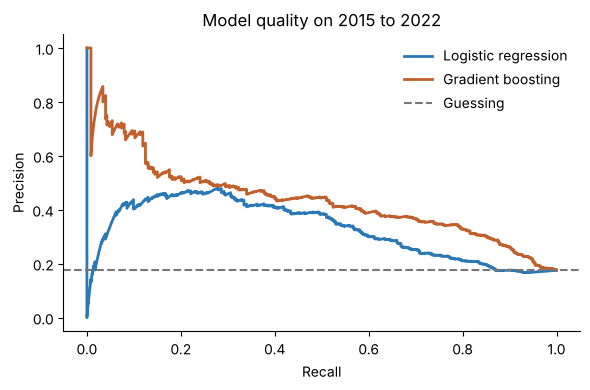

In [14]:
# Precision and recall on test days. The dashed line is what guessing gives.
fig, ax = plt.subplots(figsize=(6, 4))
for (name, (precision, recall, _)), color in zip(curves.items(), ["#2a78b5", "#c1602c"]):
    ax.plot(recall, precision, label=name, color=color, linewidth=2)
ax.axhline(test_target.mean(), color="#777777", linestyle="--", label="Guessing")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Model quality on 2015 to 2022")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("ml_precision_recall.png", dpi=200)
plt.show()

## Step 7. Which inputs matter?
For logistic regression, inputs were rescaled first, so sizes can be compared. These show association, not cause.

In [15]:
logistic = fitted["Logistic regression"].named_steps["logisticregression"]
weights = pd.Series(logistic.coef_[0], index=inputs.columns).sort_values(key=np.abs, ascending=False)
weights.head(8).round(3)

gap_fixed_smooth       1.055
volatility_20          0.910
gap_adaptive_smooth   -0.877
cusum_down            -0.497
return_60             -0.487
volatility_60          0.457
adaptive_alpha        -0.390
fall_from_high_60     -0.381
dtype: float64

## Step 8. Sanity check on fake data
Real markets give only one history. On fake markets the truth is known and many runs are possible. Here we use Case B, trends with wild noise, and compare with fixed smoothing using alpha 0.1 and delta 0.03, as tuned for that case in the repo.

In [16]:
# Fake markets where the true change dates are known.
# Case A, up and down trends with calm Gaussian noise.
# Case B, the same trends with changing volatility and fat tails.
# Case C, the target leaves and rejoins related series.

import numpy as np


def _segment_starts(rng, days, low, high):
    # Pick random segment lengths until the series is full.
    starts, current = [], 0
    while True:
        current += int(rng.integers(low, high + 1))
        if current >= days - low // 2:
            return np.array(starts, dtype=int)
        starts.append(current)


def _noise(rng, days, heavy):
    # Calm Gaussian noise, or Student t noise with changing volatility.
    if not heavy:
        return rng.normal(0.0, 0.01, days)
    # Student t with 4 degrees of freedom has variance 2, so divide by root 2.
    shocks = rng.standard_t(4, days) / np.sqrt(2.0)
    level = np.empty(days)
    current, position = 0.01, 0
    while position < days:
        span = int(rng.integers(100, 300))
        level[position:position + span] = current
        current = float(rng.choice([0.006, 0.01, 0.02]))
        position += span
    return shocks * level


def _related(rng, factor, m=4):
    # Related series share the common factor and have small private noise.
    private = rng.normal(0.0, 0.003, (len(factor), m))
    return np.cumsum(factor[:, None] + private, axis=0)


def simulate_trend(seed, days=1500, heavy=False):
    # Direction flips at each planted date and the size varies by segment.
    rng = np.random.default_rng(seed)
    truth = _segment_starts(rng, days, 120, 300)
    edges = np.concatenate(([0], truth, [days]))
    drift = np.empty(days)
    sign = 1.0
    for a, b in zip(edges[:-1], edges[1:]):
        drift[a:b] = sign * rng.uniform(0.002, 0.004)
        sign = -sign
    returns = drift + _noise(rng, days, heavy)
    return {"y": np.cumsum(returns), "related": _related(rng, returns), "truth": truth}


def simulate_relationship_break(seed, days=1500):
    # The market factor has no planted reversals here.
    # During a break the target also gains its own steady drift.
    rng = np.random.default_rng(seed)
    truth = _segment_starts(rng, days, 120, 300)
    edges = np.concatenate(([0], truth, [days]))
    factor = rng.normal(0.0003, 0.01, days)
    extra = np.zeros(days)
    breaking = False
    for a, b in zip(edges[:-1], edges[1:]):
        if breaking:
            extra[a:b] = rng.choice([-1.0, 1.0]) * rng.uniform(0.002, 0.004)
        breaking = not breaking
    returns = factor + extra + rng.normal(0.0, 0.003, days)
    return {"y": np.cumsum(returns), "related": _related(rng, factor), "truth": truth}


CASES = {
    "A clean trends": lambda seed, days: simulate_trend(seed, days, False),
    "B wild noise": lambda seed, days: simulate_trend(seed, days, True),
    "C relationship breaks": simulate_relationship_break,
}

In [17]:
def stacked_runs(seeds):
    # Join several fake markets into one training table.
    X, target = [], []
    for seed in seeds:
        run = simulate_trend(seed, 1500, True)
        part = make_features(run["y"], run["related"]).ffill().fillna(0.0).iloc[250:]
        X.append(part)
        target.append(make_target(run["truth"], 1500)[250:])
    return pd.concat(X), np.concatenate(target)


X_train, target_train = stacked_runs(range(500000, 500030))
simulation_model = models()["Gradient boosting"].fit(X_train, target_train)


def simulation_f1(level, seeds):
    # Average F1 for the model and for the rule on the same runs.
    model_scores, rule_scores = [], []
    for seed in seeds:
        run = simulate_trend(seed, 1500, True)
        part = make_features(run["y"], run["related"]).ffill().fillna(0.0)
        prob = simulation_model.predict_proba(part.iloc[250:])[:, 1]
        real = inside(run["truth"], 250, 1500)
        model_scores.append(score(real, probability_alarms(prob, 250, level), TOLERANCE)["f1"])
        days = np.array([d for d, _ in fixed_smoothing_alarms(run["y"], 0.1, 0.03)], dtype=int)
        rule_scores.append(score(real, inside(days, 250, 1500), TOLERANCE)["f1"])
    return np.array(model_scores), np.array(rule_scores)


simulation_level = max(levels, key=lambda v: simulation_f1(v, range(510000, 510010))[0].mean())
model_f1, rule_f1 = simulation_f1(simulation_level, range(520000, 520050))
print("Alarm level", simulation_level)
print("Model F1", round(model_f1.mean(), 3), "Rule F1", round(rule_f1.mean(), 3))

Alarm level 0.5
Model F1 0.499 Rule F1 0.627


In [18]:
# Save the numbers used by the report.
ml_table.to_csv("ml_scores.csv", index=False)
with open("ml_extra.json", "w") as handle:
    json.dump({"base_rate": float(test_target.mean()), "levels": chosen,
               "top_weights": weights.head(8).round(3).to_dict(),
               "simulation_model_f1": float(model_f1.mean()), "simulation_rule_f1": float(rule_f1.mean()),
               "simulation_level": float(simulation_level)}, handle, indent=2)
print("Saved")

Saved


## Conclusion
On the 2015 to 2022 test years, neither model beat the simple fixed smoothing rule. Gradient boosting scored F1 0.50 and logistic regression 0.44, against 0.76 for the rule. Both models still did better than random alarms, so the inputs hold real information, and gradient boosting reached an average precision of 0.44 against 0.18 from guessing. The fake market check agrees, with F1 0.50 for the model and 0.63 for the rule. A likely reason is that the answer key follows the same up and down logic as the rule, and only about 18 turning points were available to train on in the real data. The honest conclusion is that more model complexity did not help here.